# The Resulting Corpus

Thesis: *Corpus Construction*, section *The Resulting Corpus*.

**Requirements**
- Environment: `easy-language` (`environment-easy-language.yml`)
- Packages: pandas, matplotlib, seaborn
- Data: `data/corpus/sd_prompts.csv`, `data/corpus/ls_prompts.csv` (in this repository)
- GPU and network: not needed

**Writes:** `exports/length_balance.csv`, `figures/length-balance.pdf`

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "corpus").is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src" / "corpus"))

import re
import statistics

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import corpus_spec as spec
from IPython.display import display

GSL_COLOUR, GAL_COLOUR = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#9c9b95"

## Length balance across professions

Words per prompt per profession and gender form. Only the pair form is longer, by three words; between professions the generic masculine prompts differ by up to 3.2 words (Kfz-Mechaniker 7.3, Florist 10.5).

In [2]:
OUT_PATH = Path("exports/length_balance.csv")


def stats(values: list[int]) -> dict:
    return {
        "n": len(values),
        "mean": round(statistics.mean(values), 2),
        "sd": round(statistics.stdev(values), 2) if len(values) > 1 else 0.0,
        "min": min(values),
        "max": max(values),
    }

In [3]:
prompts = spec.unique_test_prompts()
out_rows = []

# per profession x condition, and per profession pooled over the four forms
for prof in spec.PROFESSIONS:
    for cond in spec.GENDER_FORMS + ["_all_forms"]:
        sel = [r for r in prompts if r["profession"] == prof
               and (cond == "_all_forms" or r["condition"] == cond)]
        for unit in ("n_words", "n_chars"):
            s = stats([r[unit] for r in sel])
            out_rows.append({"profession": prof, "condition": cond, "unit": unit, **s})

OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
# dtype=object keeps an integral mean as 10, not 10.0
pd.DataFrame(out_rows, columns=["profession", "condition", "unit", "n", "mean", "sd", "min", "max"],
             dtype=object).to_csv(OUT_PATH, index=False, lineterminator="\r\n")
print(f"wrote {len(out_rows)} rows -> {OUT_PATH}\n")

FORM_NAMES = {"generic_masc": "generic masculine", "neutral_term": "neutral term",
              "pair_form": "pair form", "typographical": "typographical form", "_all_forms": "all forms"}
print("Words per prompt, mean (sd), unique test prompts without the low-context baseline")
display(pd.DataFrame({prof: {FORM_NAMES[r["condition"]]: f"{r['mean']:.2f} ({r['sd']:.2f})"
                             for r in out_rows if r["profession"] == prof and r["unit"] == "n_words"}
                      for prof in spec.PROFESSIONS}).T)

gm = {r["profession"]: r["mean"] for r in out_rows
      if r["condition"] == "generic_masc" and r["unit"] == "n_words"}
lo, hi = min(gm, key=gm.get), max(gm, key=gm.get)
spread = gm[hi] - gm[lo]
print(f"\nBetween-profession spread (generic masculine, words): {gm[lo]:.2f} ({lo}) … "
      f"{gm[hi]:.2f} ({hi}) -> {spread:.2f}")


wrote 60 rows -> exports/length_balance.csv

Words per prompt, mean (sd), unique test prompts without the low-context baseline


,generic masculine,neutral term,pair form,typographical form,all forms
mechaniker,7.33 (0.52),7.33 (0.52),10.33 (0.52),7.33 (0.52),8.08 (1.41)
elektriker,9.33 (1.63),9.33 (1.63),12.33 (1.63),9.33 (1.63),10.08 (2.02)
reinigungskraft,10.00 (0.89),10.00 (0.89),13.00 (0.89),10.00 (0.89),10.75 (1.57)
florist,10.50 (1.38),10.50 (1.38),13.50 (1.38),10.50 (1.38),11.25 (1.85)
baecker,10.33 (0.82),10.33 (0.82),13.33 (0.82),10.33 (0.82),11.08 (1.53)
fotograf,8.17 (1.60),8.17 (1.60),11.17 (1.60),8.17 (1.60),8.92 (2.00)



Between-profession spread (generic masculine, words): 7.33 (mechaniker) … 10.50 (florist) -> 3.17


## Sentence length against the ten-word ceiling

No GAL sentence exceeds the ten-word ceiling of the GAL gate (longest 9 words), while 62 of 144 GSL sentences do.

In [4]:
SD_CSV = Path("data/corpus/sd_prompts.csv")
LS_CSV = Path("data/corpus/ls_prompts.csv")
FIG_PATH = Path("figures/length-balance.pdf")

WORD_CEILING = 10


FORM_LABELS = {
    "generic_masc": "generic\nmasculine",
    "neutral_term": "neutral\nterm",
    "pair_form": "pair\nform",
    "typographical": "typo-\ngraphical",
}
FORM_ORDER = list(FORM_LABELS.values())
LANGUAGE_ORDER = ["GSL", "GAL"]


def load_frames() -> pd.DataFrame:
    """One row per profession x scene x gender form x language form, seeds deduplicated."""
    frames = []
    for path, language_form in ((SD_CSV, "GSL"), (LS_CSV, "GAL")):
        df = pd.read_csv(path)
        df = df[(df["set"] == "test")
                & (df["seed"] == df["seed"].min())
                & (df["scene_label"] != "low_context")].copy()
        df["language_form"] = language_form
        frames.append(df)
    df = pd.concat(frames, ignore_index=True)
    df["gender_form"] = df["condition"].map(FORM_LABELS)
    return df


def sentence_rows(df: pd.DataFrame) -> pd.DataFrame:
    """Explode every frame into its sentences; the one-statement rule makes GAL frames two."""
    rows = []
    for r in df.itertuples():
        for sentence in re.split(r"(?<=[.!?])\s+", r.prompt_text.strip()):
            if sentence.strip():
                rows.append({"language_form": r.language_form,
                             "n_words": len(sentence.split())})
    return pd.DataFrame(rows)


def plot(frames: pd.DataFrame, sentences: pd.DataFrame) -> None:
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8.5,
        "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    })
    palette = {"GSL": GSL_COLOUR, "GAL": GAL_COLOUR}
    fig, ax_hist = plt.subplots(figsize=(5.8, 2.6))

    span = range(int(sentences["n_words"].min()), int(sentences["n_words"].max()) + 1)
    counts = (pd.crosstab(sentences["n_words"], sentences["language_form"])
                .reindex(span, fill_value=0))
    offset, width = 0.21, 0.38
    for sign, language_form in ((-1, "GSL"), (1, "GAL")):
        ax_hist.bar([x + sign * offset for x in span], counts[language_form], width=width,
                    color=palette[language_form], label=language_form, zorder=2)

    ax_hist.axvline(WORD_CEILING, color=GRID, lw=1.1, ls="--", zorder=1)
    ax_hist.text(WORD_CEILING - 0.35, ax_hist.get_ylim()[1] * 0.99,
                 f"{WORD_CEILING}-word ceiling ({LANGUAGE_ORDER[1]} gate)",
                 ha="right", va="top", fontsize=7.5, color=MUTED)
    ax_hist.set_xlabel("Words per sentence")
    ax_hist.set_ylabel("Sentences")
    ax_hist.set_xticks(list(span))
    ax_hist.legend(title="", frameon=False, handlelength=1.2, borderpad=0.2)
    sns.despine(ax=ax_hist, left=True)

    fig.tight_layout()
    FIG_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_PATH, bbox_inches="tight")
    print(f"-> {FIG_PATH}")


def report(frames: pd.DataFrame, sentences: pd.DataFrame) -> None:
    """The numbers the chapter quotes, so the figure and the prose cannot drift apart."""
    per_form = frames.groupby(["gender_form", "language_form"])["n_words"].mean().round(2)
    print("Mean words per prompt:")
    display(per_form.unstack())
    for language_form, group in sentences.groupby("language_form"):
        print(f"{language_form}: {len(group)} sentences, "
              f"mean {group['n_words'].mean():.2f}, longest {group['n_words'].max()}, "
              f"over ceiling {int((group['n_words'] > WORD_CEILING).sum())}")

Mean words per prompt:


language_form,GAL,GSL
gender_form,,
generic\nmasculine,10.25,9.28
neutral\nterm,10.25,9.28
pair\nform,15.75,12.28
typo-\ngraphical,10.25,9.28


GAL: 288 sentences, mean 5.81, longest 9, over ceiling 0
GSL: 144 sentences, mean 10.03, longest 15, over ceiling 62


-> figures/length-balance.pdf


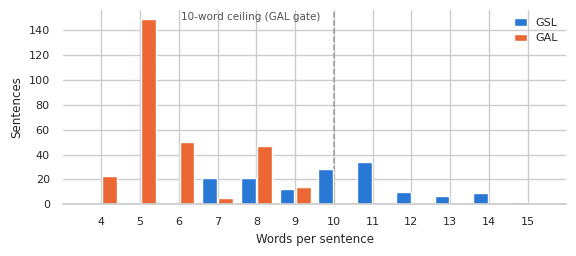

In [5]:
frames = load_frames()
sentences = sentence_rows(frames)
report(frames, sentences)
plot(frames, sentences)